
# Uczenie maszynowe — zajęcia 4
## Support Vector Machines — część 2: parametr C, dane nieliniowe i funkcje jądra

**Uniwersytet Warmińsko-Mazurski w Olsztynie**  
**Semestr 5, rok akademicki 2026/2027**  
**Prowadzący: mgr inż. Adrian Albrecht**

---

## Cel zajęć

Na poprzednich zajęciach poznaliśmy liniowy SVM i rozpoczęliśmy własną implementację.

Dzisiaj:

1. wykorzystamy własny `MyLinearSVM`,
2. sprawdzimy wpływ parametru `C`,
3. porównamy własny model z `sklearn.svm.SVC`,
4. pokażemy problem danych nieliniowo separowalnych,
5. wprowadzimy ideę transformacji przestrzeni cech,
6. omówimy **kernel trick**,
7. sprawdzimy jądra `linear`, `poly` oraz `rbf`,
8. przeanalizujemy wpływ `degree`, `gamma` i `C` na granicę decyzyjną.

> W tym notebooku nie ma implementacji `MyLinearSVM`.  
> Własna implementacja pozostaje pracą samodzielną.



## Plan zajęć — 90 minut

| Czas | Temat |
|---:|---|
| 0–15 min | Uruchomienie własnego `MyLinearSVM` |
| 15–30 min | Wpływ parametru `C` |
| 30–40 min | Porównanie z liniowym `SVC` |
| 40–55 min | Problem nieliniowej separowalności |
| 55–67 min | Transformacja przestrzeni i kernel trick |
| 67–80 min | Jądra `poly` i `rbf` |
| 80–87 min | Wpływ `degree`, `gamma` i `C` |
| 87–90 min | Zadanie samodzielne i podsumowanie |



# 0. Przygotowanie środowiska


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

np.set_printoptions(
    precision=4,
    suppress=True
)

RANDOM_STATE = 42



# 1. Własny `MyLinearSVM`

Najpierw sprawdzamy, czy dostępny jest moduł z implementacją liniowego SVM.

W materiałach udostępnionych studentom pliku z gotową implementacją może nie być — to zamierzone.


In [2]:

try:
    from mySVM import MyLinearSVM

    HAS_MY_SVM = True
    print("Znaleziono implementację.")

except ImportError:
    HAS_MY_SVM = False
    print("Nie znaleziono implementacji.")


Znaleziono implementację.



## 1.1. Dane liniowo separowalne


In [3]:

X_linear, y_linear_01 = make_blobs(
    n_samples=80,
    centers=[
        (-2.5, -2.0),
        (2.5, 2.0)
    ],
    cluster_std=0.95,
    random_state=RANDOM_STATE
)

y_linear = np.where(
    y_linear_01 == 0,
    -1,
    1
)

scaler_linear = StandardScaler()

X_linear_scaled = (
    scaler_linear.fit_transform(
        X_linear
    )
)


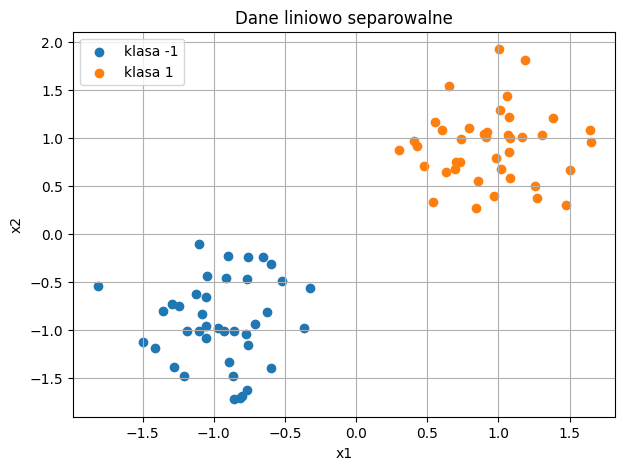

In [4]:

plt.figure(figsize=(7, 5))

for class_id in [-1, 1]:
    mask = y_linear == class_id

    plt.scatter(
        X_linear_scaled[mask, 0],
        X_linear_scaled[mask, 1],
        label=f"klasa {class_id}"
    )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Dane liniowo separowalne")
plt.legend()
plt.grid()
plt.show()



## 1.2. Funkcja pomocnicza do rysowania liniowego modelu

Ta funkcja nie implementuje SVM.

Służy wyłącznie do wizualizacji modelu, który posiada `w` oraz `b`.


In [5]:

def plot_linear_model(
    X,
    y,
    model,
    title
):
    plt.figure(
        figsize=(8, 6)
    )

    for class_id in [-1, 1]:
        mask = y == class_id

        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            label=f"klasa {class_id}"
        )

    w = model.w
    b = model.b

    x_axis = np.linspace(
        X[:, 0].min() - 0.5,
        X[:, 0].max() + 0.5,
        300
    )

    boundary = (
        -(w[0] / w[1])
        * x_axis
        - b / w[1]
    )

    margin_plus = (
        -(w[0] / w[1])
        * x_axis
        - (b - 1) / w[1]
    )

    margin_minus = (
        -(w[0] / w[1])
        * x_axis
        - (b + 1) / w[1]
    )

    plt.plot(
        x_axis,
        boundary,
        label="granica"
    )

    plt.plot(
        x_axis,
        margin_plus,
        linestyle="--",
        label="margines +1"
    )

    plt.plot(
        x_axis,
        margin_minus,
        linestyle="--",
        label="margines -1"
    )

    if (
        hasattr(
            model,
            "support_vectors_"
        )
        and model.support_vectors_
        is not None
        and len(
            model.support_vectors_
        ) > 0
    ):
        plt.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=160,
            facecolors="none",
            label="punkty na / wewnątrz marginesu"
        )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


w = [1.0168 0.9276]
b = -0.10664657051689372


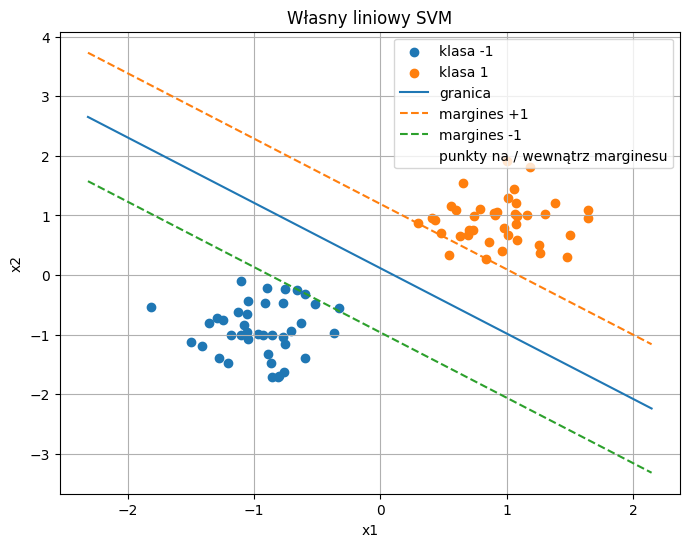

In [6]:

if HAS_MY_SVM:

    my_model = MyLinearSVM(
        learning_rate=0.0005,
        C=1.0,
        n_iterations=5000
    )

    my_model.fit(
        X_linear_scaled,
        y_linear
    )

    print("w =", my_model.w)
    print("b =", my_model.b)

    plot_linear_model(
        X_linear_scaled,
        y_linear,
        my_model,
        "Własny liniowy SVM"
    )



# 2. Wpływ parametru C

Przypomnienie funkcji celu:

$$
J(\mathbf{w},b)=
\frac{1}{2}
\left\|\mathbf{w}\right\|^2
+
C
\sum_{i=1}^{n}
\max
\left(
0,
1-y_i
\left(
\mathbf{w}^T\mathbf{x}_i+b
\right)
\right)
$$

`C` reguluje kompromis pomiędzy:

- szerokim marginesem,
- karaniem naruszeń marginesu.

### Małe `C`

Model może zaakceptować więcej naruszeń.

### Duże `C`

Naruszenia są droższe.



Do eksperymentu użyjemy trudniejszych danych, w których klasy częściowo na siebie nachodzą.


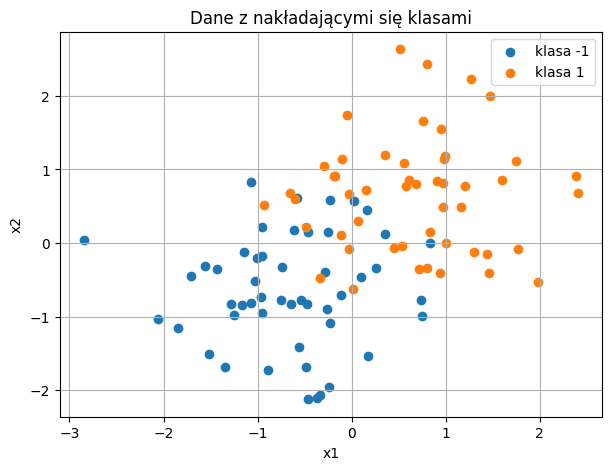

In [7]:

X_overlap, y_overlap_01 = make_blobs(
    n_samples=100,
    centers=[
        (-1.0, -1.0),
        (1.0, 1.0)
    ],
    cluster_std=1.35,
    random_state=RANDOM_STATE
)

y_overlap = np.where(
    y_overlap_01 == 0,
    -1,
    1
)

scaler_overlap = StandardScaler()

X_overlap_scaled = (
    scaler_overlap.fit_transform(
        X_overlap
    )
)

plt.figure(figsize=(7, 5))

for class_id in [-1, 1]:
    mask = y_overlap == class_id

    plt.scatter(
        X_overlap_scaled[mask, 0],
        X_overlap_scaled[mask, 1],
        label=f"klasa {class_id}"
    )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Dane z nakładającymi się klasami")
plt.legend()
plt.grid()
plt.show()


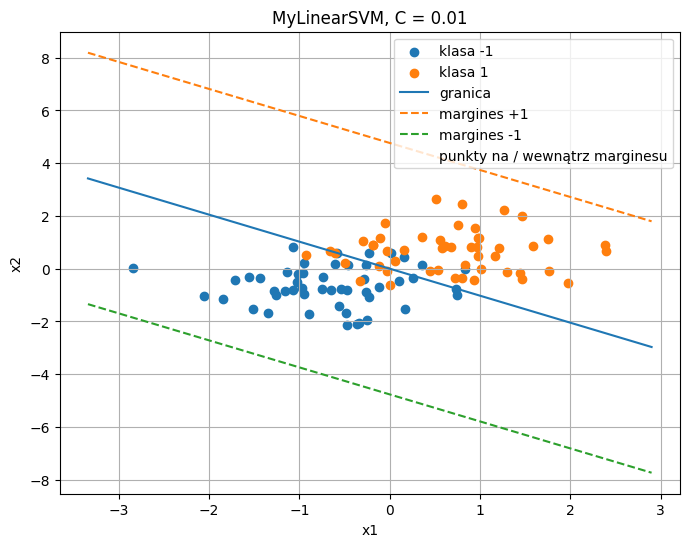

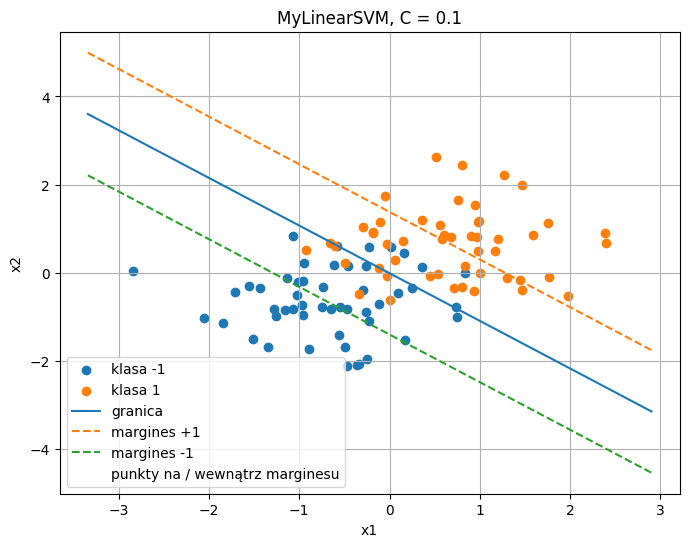

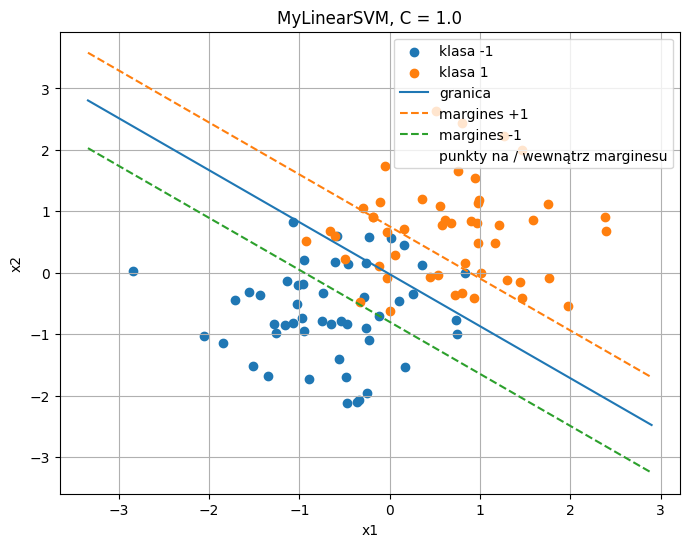

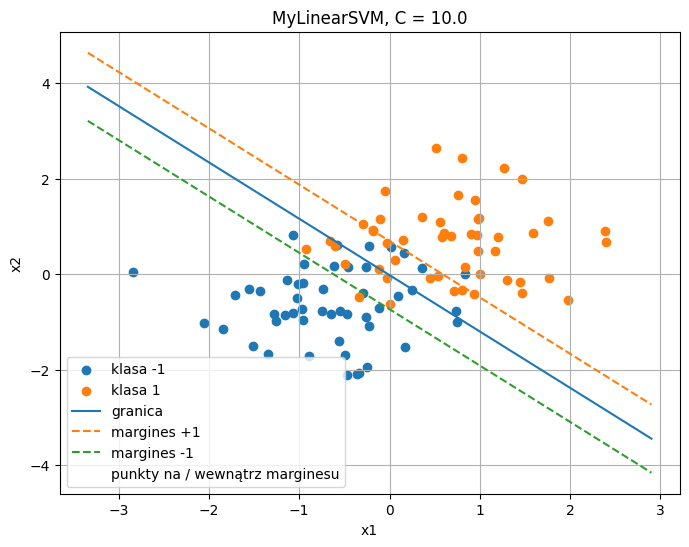

In [8]:

if HAS_MY_SVM:

    C_values = [
        0.01,
        0.1,
        1.0,
        10.0
    ]

    for C_value in C_values:

        model = MyLinearSVM(
            learning_rate=0.0002,
            C=C_value,
            n_iterations=6000
        )

        model.fit(
            X_overlap_scaled,
            y_overlap
        )

        plot_linear_model(
            X_overlap_scaled,
            y_overlap,
            model,
            f"MyLinearSVM, C = {C_value}"
        )



### Co obserwować?

Nie pytamy tutaj:

> „Które C daje najlepszą dokładność?”

Interesuje nas **zachowanie algorytmu**:

- jak zmienia się szerokość marginesu,
- ile punktów znajduje się wewnątrz marginesu,
- jak przesuwa się granica,
- jak model reaguje na obserwacje trudne do rozdzielenia.

To jest właśnie znaczenie hiperparametru `C`.



# 3. Porównanie z `sklearn.svm.SVC`

Teraz możemy użyć gotowej implementacji.

Dla liniowego jądra:

```python
SVC(kernel="linear")
```

buduje liniowy klasyfikator SVM.

Nie oczekujemy identycznych wartości `w` i `b`, ponieważ nasza implementacja używa prostego subgradient descent, a `SVC` wykorzystuje bardziej zaawansowany solver.


In [9]:

svc_linear = SVC(
    kernel="linear",
    C=1.0
)

svc_linear.fit(
    X_linear_scaled,
    y_linear
)

print("SVC — w:")
print(
    svc_linear.coef_[0]
)

print("\nSVC — b:")
print(
    svc_linear.intercept_[0]
)

print("\nLiczba wektorów wspierających:")
print(
    svc_linear.n_support_
)


SVC — w:
[1.0119 0.9418]

SVC — b:
-0.10633614921737279

Liczba wektorów wspierających:
[2 2]



## 3.1. Wizualizacja `SVC`


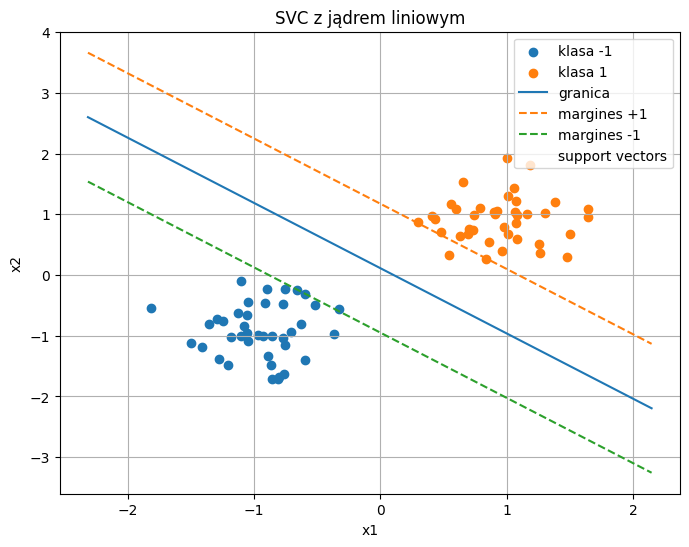

In [10]:

def plot_svc_linear(
    X,
    y,
    model,
    title
):
    plt.figure(
        figsize=(8, 6)
    )

    for class_id in [-1, 1]:
        mask = y == class_id

        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            label=f"klasa {class_id}"
        )

    w = model.coef_[0]
    b = model.intercept_[0]

    x_axis = np.linspace(
        X[:, 0].min() - 0.5,
        X[:, 0].max() + 0.5,
        300
    )

    boundary = (
        -(w[0] / w[1])
        * x_axis
        - b / w[1]
    )

    margin_plus = (
        -(w[0] / w[1])
        * x_axis
        - (b - 1) / w[1]
    )

    margin_minus = (
        -(w[0] / w[1])
        * x_axis
        - (b + 1) / w[1]
    )

    plt.plot(
        x_axis,
        boundary,
        label="granica"
    )

    plt.plot(
        x_axis,
        margin_plus,
        linestyle="--",
        label="margines +1"
    )

    plt.plot(
        x_axis,
        margin_minus,
        linestyle="--",
        label="margines -1"
    )

    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=160,
        facecolors="none",
        label="support vectors"
    )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


plot_svc_linear(
    X_linear_scaled,
    y_linear,
    svc_linear,
    "SVC z jądrem liniowym"
)



# 4. Problem danych nieliniowych

Liniowa hiperpłaszczyzna działa tylko wtedy, gdy struktura problemu może być sensownie rozdzielona liniowo.

Sprawdźmy dane typu `make_moons`.


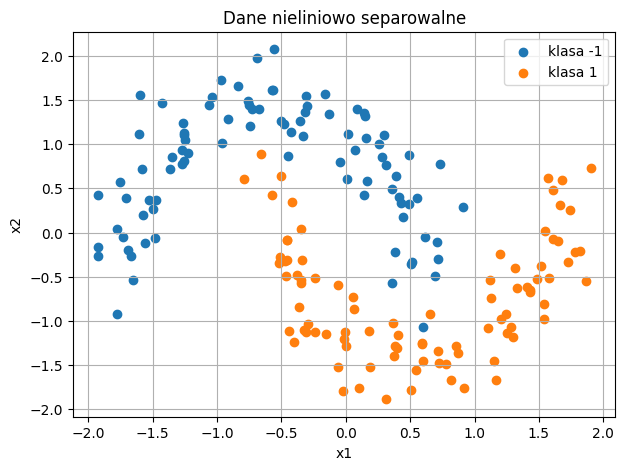

In [11]:

X_moons, y_moons_01 = make_moons(
    n_samples=180,
    noise=0.14,
    random_state=RANDOM_STATE
)

y_moons = np.where(
    y_moons_01 == 0,
    -1,
    1
)

scaler_moons = StandardScaler()

X_moons_scaled = (
    scaler_moons.fit_transform(
        X_moons
    )
)

plt.figure(figsize=(7, 5))

for class_id in [-1, 1]:
    mask = y_moons == class_id

    plt.scatter(
        X_moons_scaled[mask, 0],
        X_moons_scaled[mask, 1],
        label=f"klasa {class_id}"
    )

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Dane nieliniowo separowalne")
plt.legend()
plt.grid()
plt.show()



Spróbujmy liniowego `SVC`.


In [12]:

svc_moons_linear = SVC(
    kernel="linear",
    C=1.0
)

svc_moons_linear.fit(
    X_moons_scaled,
    y_moons
)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False



# 5. Funkcja do wizualizacji dowolnej granicy SVC

Dla jąder nieliniowych nie możemy już po prostu narysować jednej prostej z `coef_`.

Zamiast tego tworzymy gęstą siatkę punktów i pytamy model, po której stronie granicy znajduje się każdy z nich.


In [13]:

def plot_svc_boundary(
    X,
    y,
    model,
    title
):
    x_min = (
        X[:, 0].min() - 0.6
    )
    x_max = (
        X[:, 0].max() + 0.6
    )

    y_min = (
        X[:, 1].min() - 0.6
    )
    y_max = (
        X[:, 1].max() + 0.6
    )

    xx, yy = np.meshgrid(
        np.linspace(
            x_min,
            x_max,
            300
        ),
        np.linspace(
            y_min,
            y_max,
            300
        )
    )

    grid = np.column_stack([
        xx.ravel(),
        yy.ravel()
    ])

    Z = model.decision_function(
        grid
    )

    Z = Z.reshape(
        xx.shape
    )

    plt.figure(
        figsize=(8, 6)
    )

    for class_id in [-1, 1]:
        mask = y == class_id

        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            label=f"klasa {class_id}"
        )

    plt.contour(
        xx,
        yy,
        Z,
        levels=[-1, 0, 1],
        linestyles=[
            "--",
            "-",
            "--"
        ]
    )

    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=130,
        facecolors="none",
        label="support vectors"
    )

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


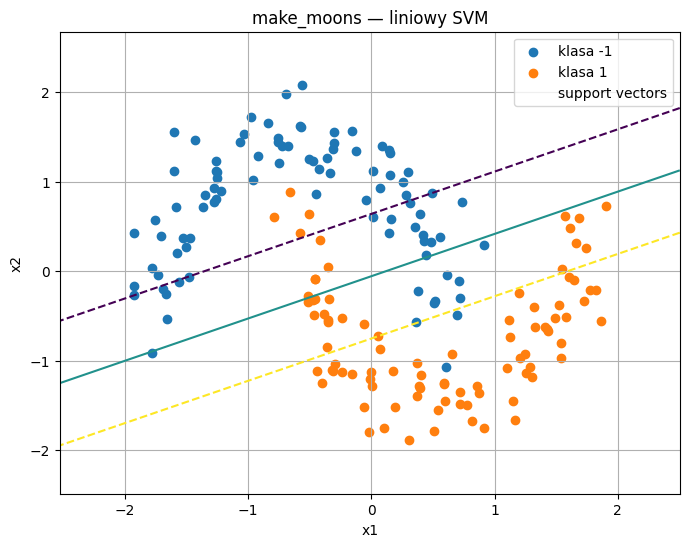

In [14]:

plot_svc_boundary(
    X_moons_scaled,
    y_moons,
    svc_moons_linear,
    "make_moons — liniowy SVM"
)



Liniowa granica nie jest w stanie odwzorować zakrzywionej struktury danych.

Potrzebujemy innego pomysłu.



# 6. Transformacja przestrzeni cech

Wyobraźmy sobie, że dane są trudne do rozdzielenia w oryginalnej przestrzeni:

$$
(x_1,x_2)
$$

Możemy utworzyć nowe cechy, np.:

$$
z_1=x_1
$$

$$
z_2=x_2
$$

$$
z_3=x_1^2+x_2^2
$$

W nowej przestrzeni problem może stać się łatwiejszy do liniowej separacji.

Ogólnie możemy zapisać transformację jako:

$$
\phi(\mathbf{x})
$$

i liniowy klasyfikator w nowej przestrzeni:

$$
\mathbf{w}^T
\phi(\mathbf{x})
+b=0
$$



## Problem

Jawne tworzenie bardzo dużej liczby nowych cech może być kosztowne.

Dla bardziej złożonych transformacji liczba wymiarów może być ogromna.

Tu pojawia się **kernel trick**.



# 7. Kernel trick

W problemie dualnym SVM obserwacje pojawiają się poprzez iloczyny skalarne.

Zamiast jawnie liczyć:

$$
\phi(\mathbf{x}_i)^T
\phi(\mathbf{x}_j)
$$

możemy użyć funkcji jądra:

$$
K(\mathbf{x}_i,\mathbf{x}_j)
$$

takiej, że:

$$
K(\mathbf{x}_i,\mathbf{x}_j)
=
\phi(\mathbf{x}_i)^T
\phi(\mathbf{x}_j)
$$

Dzięki temu możemy pracować **tak, jakby dane zostały przeniesione do innej przestrzeni**, bez jawnego tworzenia wszystkich nowych cech.

To właśnie nazywamy **kernel trick**.



# 8. Jądro wielomianowe

Jednym z popularnych jąder jest jądro wielomianowe.

W uproszczonej postaci:

$$
K(\mathbf{x},\mathbf{z})
=
\left(
\gamma
\mathbf{x}^T\mathbf{z}
+r
\right)^d
$$

gdzie:

- `d` odpowiada parametrowi `degree`,
- `gamma` wpływa na skalę iloczynu,
- `r` odpowiada parametrowi `coef0`.


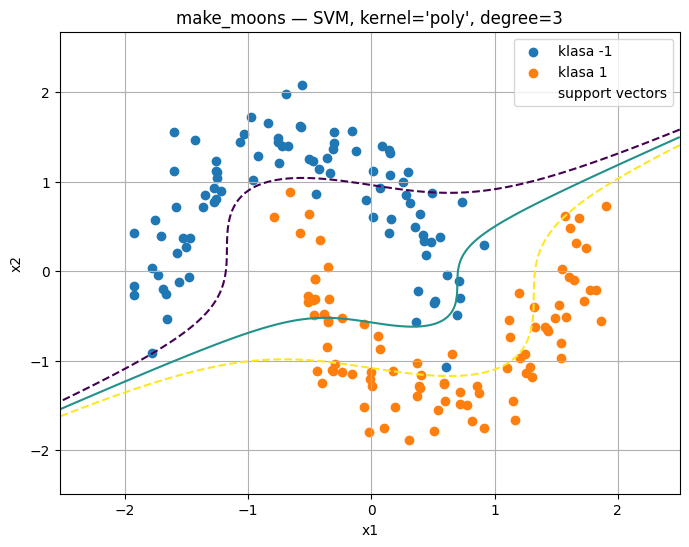

In [15]:

svc_poly = SVC(
    kernel="poly",
    degree=3,
    C=1.0,
    gamma="scale"
)

svc_poly.fit(
    X_moons_scaled,
    y_moons
)

plot_svc_boundary(
    X_moons_scaled,
    y_moons,
    svc_poly,
    "make_moons — SVM, kernel='poly', degree=3"
)



# 9. Jądro RBF

Bardzo popularnym jądrem jest **Radial Basis Function**:

$$
K(\mathbf{x},\mathbf{z})
=
\exp
\left(
-\gamma
\left\|
\mathbf{x}-\mathbf{z}
\right\|^2
\right)
$$

Wartość zależy od odległości pomiędzy punktami.

Jeżeli punkty są blisko, jądro przyjmuje większą wartość.

Jeżeli są daleko, wartość szybko maleje.


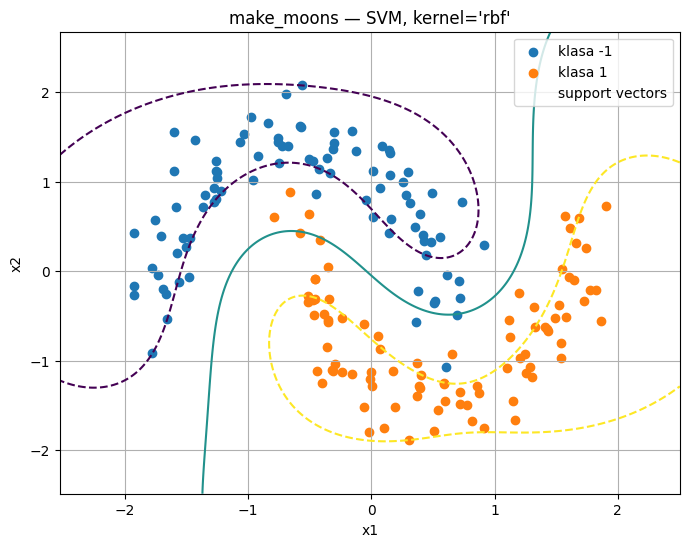

In [16]:

svc_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

svc_rbf.fit(
    X_moons_scaled,
    y_moons
)

plot_svc_boundary(
    X_moons_scaled,
    y_moons,
    svc_rbf,
    "make_moons — SVM, kernel='rbf'"
)



# 10. Wpływ gamma w RBF

`gamma` określa, jak lokalny jest wpływ pojedynczych obserwacji.

### Małe `gamma`

Wpływ punktu rozciąga się na większy obszar.

Granica jest zwykle bardziej gładka.

### Duże `gamma`

Wpływ punktu jest bardziej lokalny.

Granica może silnie wyginać się wokół danych.


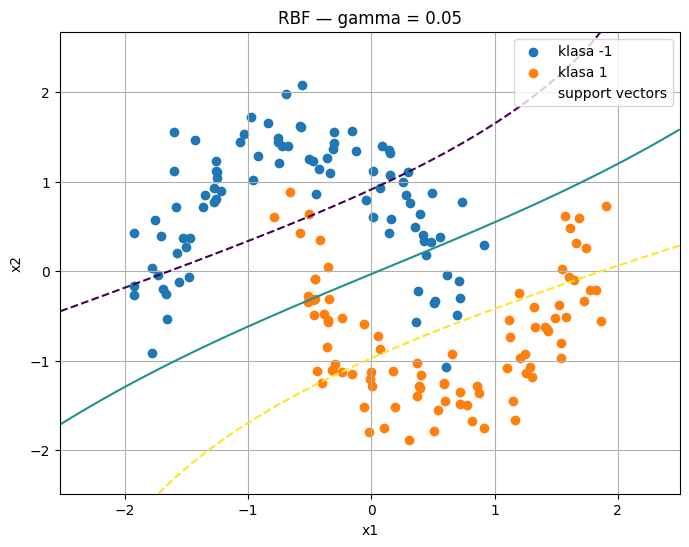

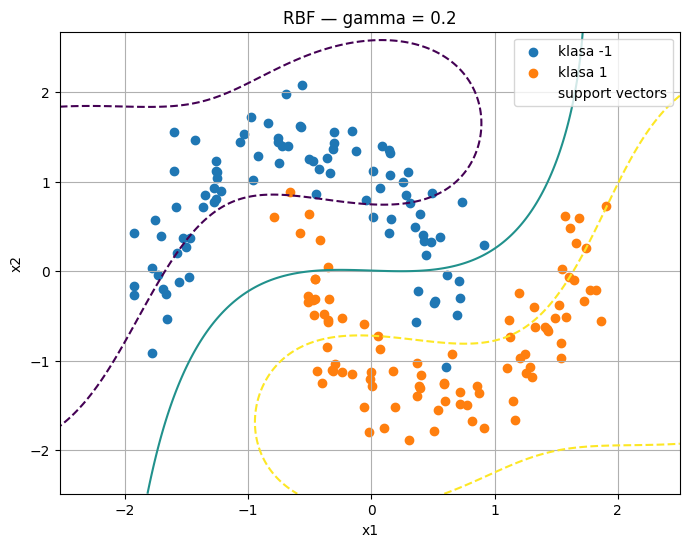

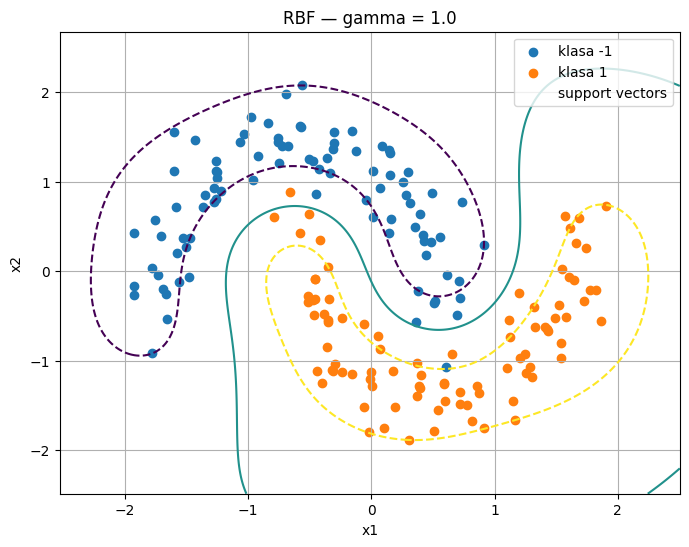

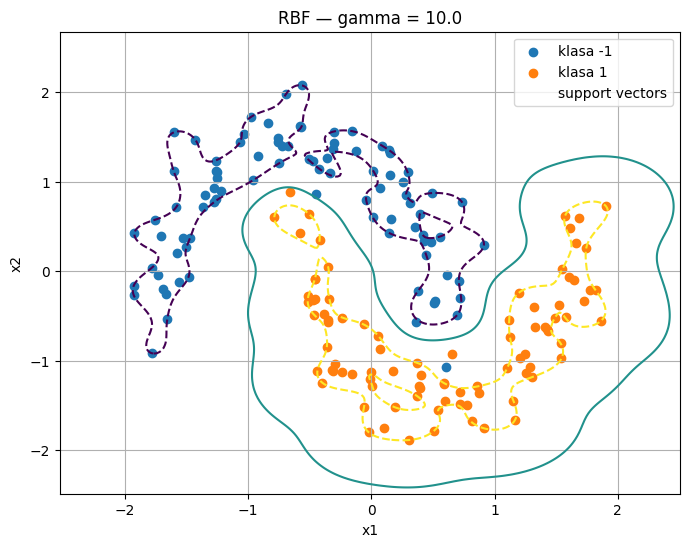

In [17]:

gamma_values = [
    0.05,
    0.2,
    1.0,
    10.0
]

for gamma_value in gamma_values:

    model = SVC(
        kernel="rbf",
        C=1.0,
        gamma=gamma_value
    )

    model.fit(
        X_moons_scaled,
        y_moons
    )

    plot_svc_boundary(
        X_moons_scaled,
        y_moons,
        model,
        f"RBF — gamma = {gamma_value}"
    )



### Co obserwować?

Nie chodzi o wybór „najlepszego wykresu”.

Zwróć uwagę:

- jak bardzo granica reaguje na lokalne szczegóły,
- jak zmienia się jej krzywizna,
- jak zmienia się liczba wektorów wspierających,
- czy granica staje się bardzo złożona.



# 11. Wspólne działanie C i gamma

W RBF jednocześnie działają co najmniej dwa ważne hiperparametry:

- `C`,
- `gamma`.

`C` określa koszt naruszeń.

`gamma` określa zasięg wpływu obserwacji.

Dlatego ta sama wartość `gamma` może zachowywać się inaczej dla różnych wartości `C`.


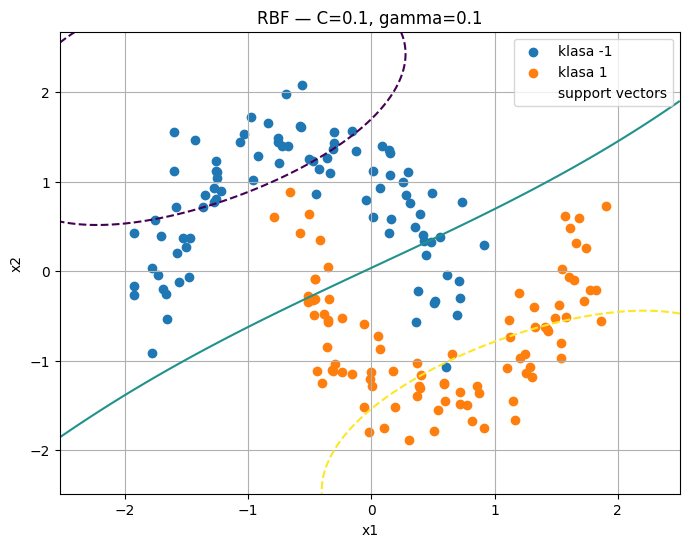

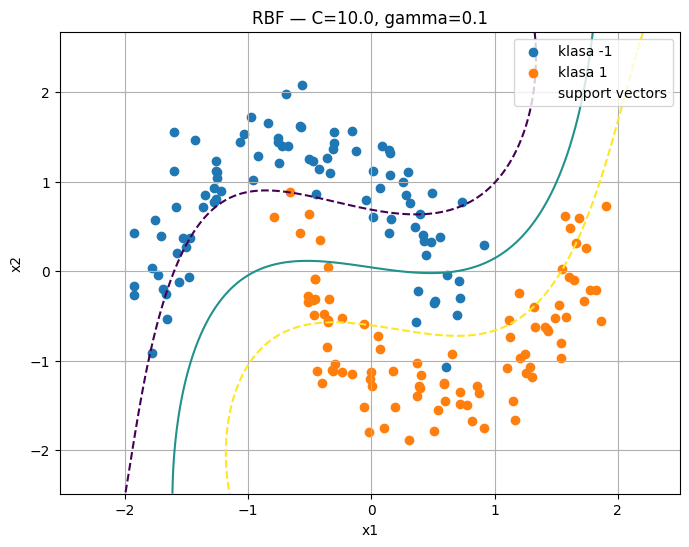

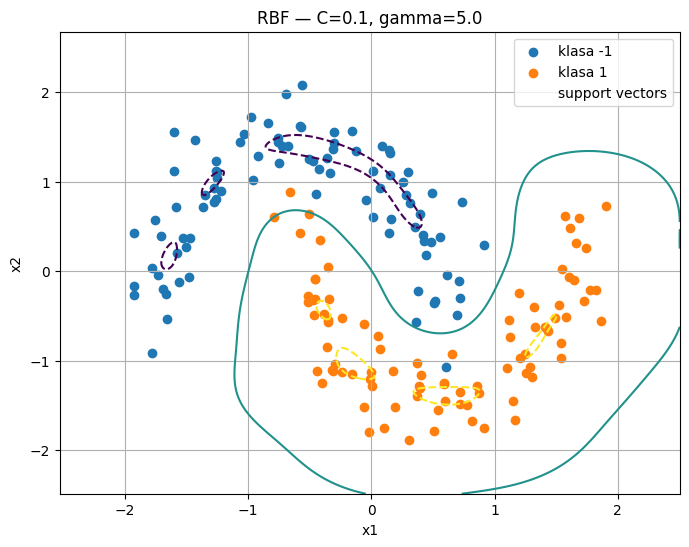

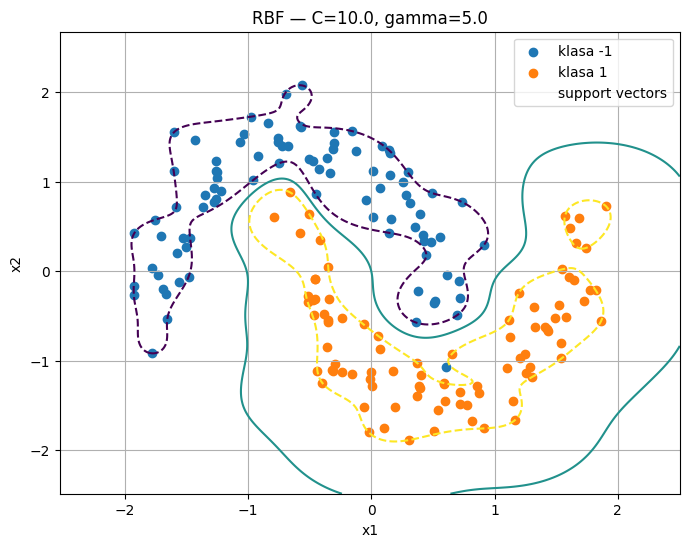

In [18]:

parameter_sets = [
    (0.1, 0.1),
    (10.0, 0.1),
    (0.1, 5.0),
    (10.0, 5.0)
]

for C_value, gamma_value in parameter_sets:

    model = SVC(
        kernel="rbf",
        C=C_value,
        gamma=gamma_value
    )

    model.fit(
        X_moons_scaled,
        y_moons
    )

    plot_svc_boundary(
        X_moons_scaled,
        y_moons,
        model,
        (
            f"RBF — C={C_value}, "
            f"gamma={gamma_value}"
        )
    )



# 12. Wpływ degree w jądrze wielomianowym

Parametr `degree` określa stopień jądra wielomianowego.

Sprawdźmy kilka wartości.


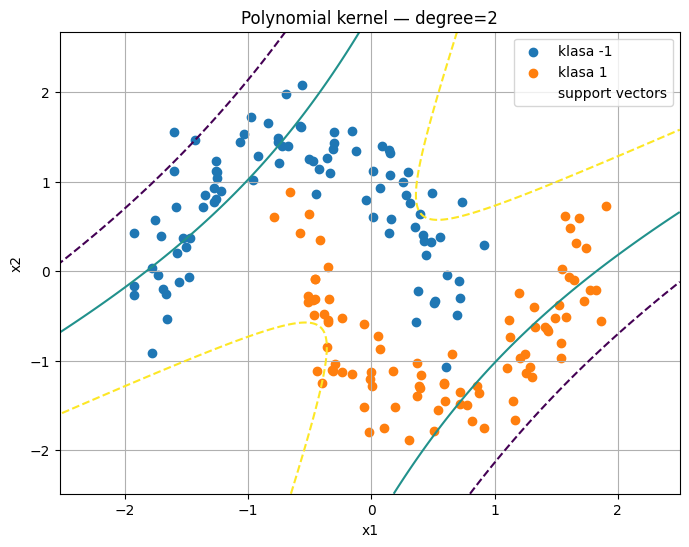

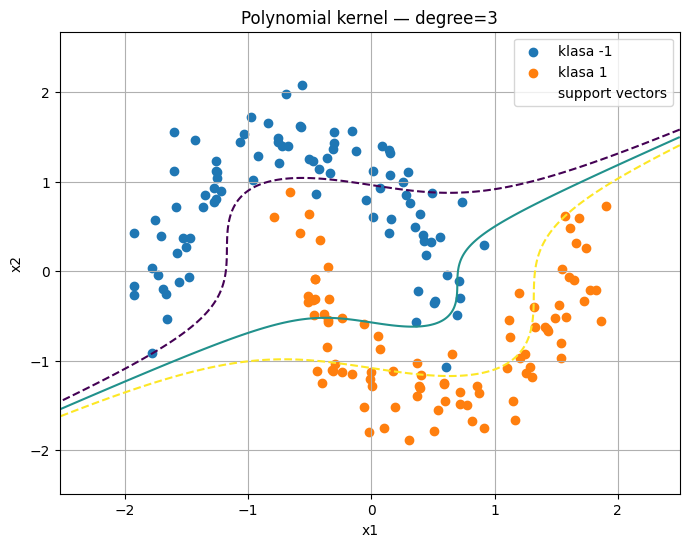

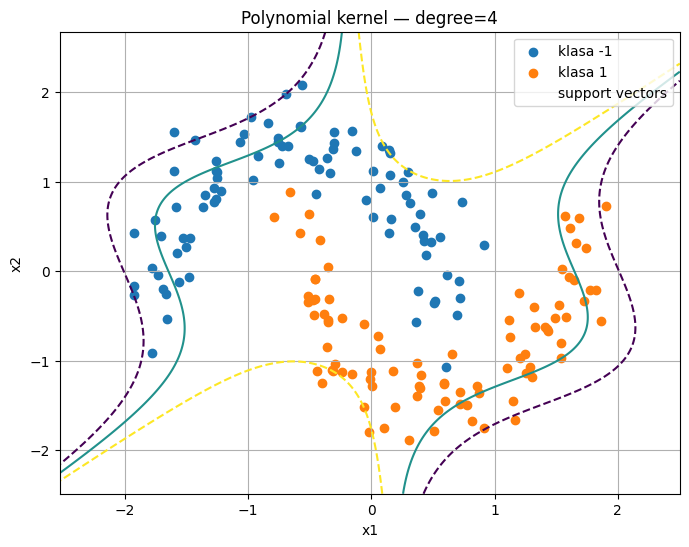

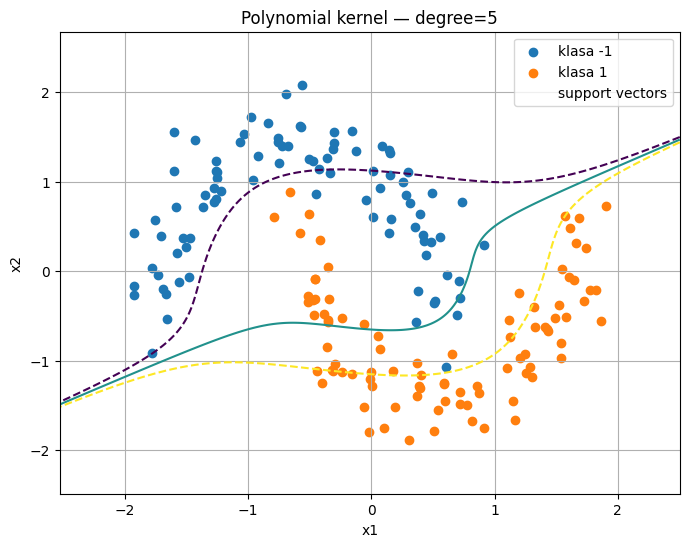

In [19]:

for degree_value in [
    2,
    3,
    4,
    5
]:

    model = SVC(
        kernel="poly",
        degree=degree_value,
        C=1.0,
        gamma="scale"
    )

    model.fit(
        X_moons_scaled,
        y_moons
    )

    plot_svc_boundary(
        X_moons_scaled,
        y_moons,
        model,
        (
            "Polynomial kernel — "
            f"degree={degree_value}"
        )
    )



# 13. Jeszcze jeden przykład — koncentryczne okręgi

`make_circles` bardzo dobrze pokazuje problem, dla którego jedna prosta nie może rozdzielić klas.


In [20]:

X_circles, y_circles_01 = make_circles(
    n_samples=180,
    factor=0.4,
    noise=0.08,
    random_state=RANDOM_STATE
)

y_circles = np.where(
    y_circles_01 == 0,
    -1,
    1
)

scaler_circles = StandardScaler()

X_circles_scaled = (
    scaler_circles.fit_transform(
        X_circles
    )
)


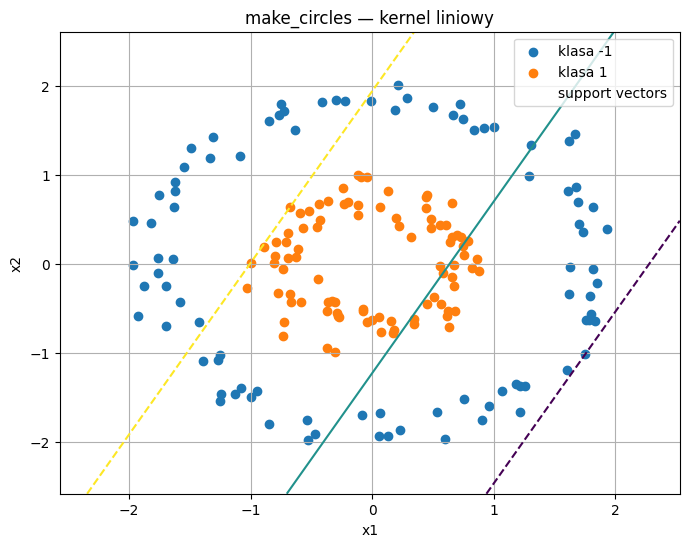

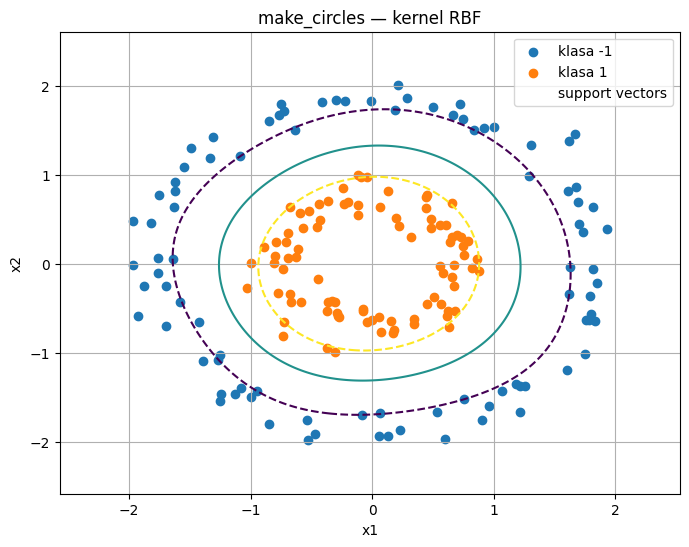

In [21]:

linear_circle = SVC(
    kernel="linear",
    C=1.0
)

rbf_circle = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

linear_circle.fit(
    X_circles_scaled,
    y_circles
)

rbf_circle.fit(
    X_circles_scaled,
    y_circles
)

plot_svc_boundary(
    X_circles_scaled,
    y_circles,
    linear_circle,
    "make_circles — kernel liniowy"
)

plot_svc_boundary(
    X_circles_scaled,
    y_circles,
    rbf_circle,
    "make_circles — kernel RBF"
)



# 14. Ważne rozróżnienie

Nasza własna implementacja `MyLinearSVM` realizuje **liniowy SVM**.

Nie implementujemy samodzielnie pełnego mechanizmu jąder.

Dlaczego?

Kernel SVM jest naturalnie związany z dualną postacią problemu optymalizacyjnego i wymaga bardziej zaawansowanego solvera.

Na tym etapie celem jest:

- rozumieć liniowy SVM od środka,
- rozumieć ideę transformacji przestrzeni,
- rozumieć kernel trick,
- poprawnie eksperymentować z gotowymi jądrami.



# 15. Zadanie samodzielne

Wykorzystaj `make_moons` albo `make_circles`.

Przeprowadź eksperyment z:

1. `kernel="linear"`,
2. `kernel="poly"`,
3. `kernel="rbf"`.

Dla `poly` sprawdź co najmniej:

```text
degree = 2, 3, 4, 5
```

Dla `rbf` sprawdź co najmniej:

```text
gamma = 0.05, 0.2, 1, 5, 10
```

Następnie dla wybranych wartości `gamma` zmień:

```text
C = 0.1, 1, 10
```

### Odpowiedz własnymi słowami

- Dlaczego liniowy SVM nie radzi sobie z tym problemem?
- Jak zmienia się granica dla kolejnych wartości `degree`?
- Jak zmienia się granica po zwiększeniu `gamma`?
- Jaką inną rolę pełni `C`, a jaką `gamma`?
- Co oznacza kernel trick?
- Czy SVM z RBF jawnie tworzy wszystkie nowe cechy?

> Nie ograniczaj się do uruchomienia kodu. Najważniejsza jest interpretacja tego, co zmieniło się na wykresach.



# 16. Pytania podsumowujące

1. Co zmienia parametr `C`?
2. Dlaczego bardzo duże `C` nie musi być zawsze korzystne?
3. Dlaczego własny `MyLinearSVM` i `SVC(kernel="linear")` mogą zwrócić trochę inne parametry?
4. Dlaczego liniowy SVM nie rozdzieli poprawnie dwóch koncentrycznych okręgów?
5. Co oznacza transformacja `phi(x)`?
6. Dlaczego jawne przechodzenie do bardzo wysokiego wymiaru może być kosztowne?
7. Na czym polega kernel trick?
8. Co oblicza funkcja jądra?
9. Jak działa jądro wielomianowe?
10. Co oznacza `degree`?
11. Jak działa RBF?
12. Co oznacza `gamma`?
13. Co zwykle dzieje się z granicą przy bardzo dużym `gamma`?
14. Czym różni się rola `C` od roli `gamma`?
15. Czy RBF tworzy jedną prostą granicę w oryginalnej przestrzeni?
16. Dlaczego przed SVM warto zwrócić uwagę na skalę cech?
17. Czym różni się liniowy SVM napisany samodzielnie od pełnego `SVC`?



# 17. Najważniejsze wnioski

> **Parametr `C` kontroluje kompromis pomiędzy szerokością marginesu a karaniem jego naruszeń.**

> **Liniowy SVM ma ograniczenie: jego granica w oryginalnej przestrzeni jest liniowa.**

> **Kernel trick pozwala operować tak, jakby dane zostały przeniesione do innej przestrzeni cech, bez jawnego konstruowania wszystkich nowych cech.**

> **Jądro wielomianowe oraz RBF pozwalają tworzyć nieliniowe granice decyzyjne.**

> **`gamma` i `C` wpływają na model w inny sposób i należy rozumieć ich znaczenie, a nie traktować ich jako przypadkowych liczb do strojenia.**

Na kolejnych zajęciach przechodzimy do **reguły Hebba**.
